# Amharic ⇄ Afan Oromo NLLB Fine-tuning (Bidirectional, Dual-GPU DDP)

**Task:** a single fine-tuned model that translates **both directions** —
Amharic → Afan Oromo *and* Afan Oromo → Amharic — from one parallel corpus
of ~11,800 children's-education sentence pairs (history, math, and other
mixed topics for ages 5–12).

## Model choice — `facebook/nllb-200-distilled-600M`

This is the same base model used in the Amharic↔English project, and it's
the right choice here for concrete reasons, not just consistency:

- **It already knows both languages.** NLLB-200's FLORES-200 language list
  includes `amh_Ethi` (Amharic) and `gaz_Latn` (West Central Oromo, the
  code covering Afan Oromo). Fine-tuning only has to *sharpen* an existing
  skill, not teach the model Oromo from scratch — which matters a lot with
  only ~11.8k pairs.
- **It's genuinely a "few-parameter" model** in the NLLB family: 600M
  parameters is the smallest official distilled NLLB-200 checkpoint (the
  larger siblings are 1.3B/3.3B). It fits and trains on Kaggle's free T4
  GPUs, which the bigger checkpoints cannot do comfortably.
- **It's one model for both directions.** NLLB is trained many-to-many, so
  a single fine-tune, fed examples tagged in both directions, learns
  `amh_Ethi→gaz_Latn` and `gaz_Latn→amh_Ethi` simultaneously — no need for
  two separate models.

## How "bidirectional, simultaneous" is implemented

Every sentence pair `(am, om)` is expanded into **two training examples**:
`am → om` (tagged `amh_Ethi`→`gaz_Latn`) and `om → am` (tagged
`gaz_Latn`→`amh_Ethi`). Both directions are trained in the same
`Trainer.train()` call, on the same shared weights — that's what makes it
"simultaneous" rather than two separate fine-tunes.

**Important ordering detail:** the train/val/test split happens on the
*original* (non-duplicated) pairs first, and only then is each split
expanded into both directions. If you duplicated directions before
splitting, the same sentence could leak across train and test (just
translated the other way), inflating your evaluation scores.

## "Word-level, context-based" evaluation

On top of BLEU, this notebook adds:
- **chrF++**, a character/word-n-gram metric that's more forgiving of the
  rich morphology in both Amharic and Oromo (a single word can carry a
  prefix/suffix that changes meaning; chrF++ credits partial matches that
  whole-word BLEU misses).
- **Word overlap**, a simple, readable-to-a-non-expert metric: what
  fraction of the reference sentence's words appear in the model's output.
- A **word/subword alignment heatmap** (Step 9) that visualizes which
  source tokens the model attended to when generating each output token —
  this is the most direct way to *see* word-level context at work.

## Data format expected

Two pipe-separated files, aligned by a shared `ID`, e.g.:
```
ID_00001|Aksuumin takkaa Galaana Diimaatti dhihoo irratti argamuu isheetiin wiirtuu daldalaa guddaa ta'uu danda'teetti.
```
(Afan Oromo) and the matching line in the Amharic file. The loader below
joins on `ID` rather than assuming line order matches — safer if the two
files ever get out of sync.

**Before running:** set the Kaggle accelerator to **GPU T4 x2**. With only
~11.8k pairs (23.6k after bidirectional expansion) this is a much smaller
job than the six-domain Amharic-English corpus, so training should finish
well within Kaggle's session limits even with per-epoch evaluation.


## Step 1 — Load and merge the two files by ID

Parses `ID|sentence` lines from both files, keeps only IDs present in
**both**, and applies light script-appropriate normalization:
- Amharic: the same homophone-character normalization used previously
  (ሃ/ሐ/ሓ/ኀ/ኃ/ኸ → ሀ, ሠ/ሧ → ሰ/ሶ, ዐ/ዓ → አ) plus quote/whitespace cleanup.
- Afan Oromo (Qubee Latin script): Unicode NFC, quote normalization, and
  whitespace/trailing-punctuation cleanup — no character substitutions
  needed since Qubee orthography doesn't have Amharic's homophone-letter
  ambiguity.


In [1]:
import os
import re
import unicodedata
import pandas as pd

AM_PATH = "/kaggle/input/datasets/fenetitefera/afanoromo-amharic-pair/amharic.txt"
OM_PATH = "/kaggle/input/datasets/fenetitefera/afanoromo-amharic-pair/afanoromo.txt"

def load_id_text(path):
    data = {}
    with open(path, encoding="utf-8") as f:
        for line in f:
            line = line.rstrip("\n")
            if not line.strip() or "|" not in line:
                continue
            sid, text = line.split("|", 1)
            data[sid.strip()] = text.strip()
    return data

am_map = load_id_text(AM_PATH)
om_map = load_id_text(OM_PATH)
print(f"Amharic lines: {len(am_map)} | Oromo lines: {len(om_map)}")

common_ids = sorted(set(am_map) & set(om_map))
only_am = set(am_map) - set(om_map)
only_om = set(om_map) - set(am_map)
print(f"Matched pairs: {len(common_ids)}")
if only_am:
    print(f"WARNING: {len(only_am)} IDs only in Amharic file (dropped), e.g. {list(only_am)[:5]}")
if only_om:
    print(f"WARNING: {len(only_om)} IDs only in Oromo file (dropped), e.g. {list(only_om)[:5]}")


Amharic lines: 11800 | Oromo lines: 11800
Matched pairs: 11800


In [2]:
def normalize_quotes(text):
    return (text.replace("\u201c", '"').replace("\u201d", '"')
                .replace("\u2018", "'").replace("\u2019", "'"))

def clean_trailing(text):
    text = text.strip()
    text = re.sub(r"\s*\.\s*\.\s*$", ".", text)
    text = re.sub(r"\.{2,}$", ".", text)
    return text

def normalize_amharic(text):
    text = unicodedata.normalize("NFC", text)
    replacements = {
        "ሃ": "ሀ", "ሐ": "ሀ", "ሓ": "ሀ", "ኀ": "ሀ", "ኃ": "ሀ", "ኸ": "ሀ",
        "ሠ": "ሰ", "ሧ": "ሶ", "ዐ": "አ", "ዓ": "አ",
    }
    for k, v in replacements.items():
        text = text.replace(k, v)
    text = normalize_quotes(text)
    text = re.sub(r"\s+", " ", text)
    return clean_trailing(text)

def normalize_oromo(text):
    text = unicodedata.normalize("NFC", text)
    text = normalize_quotes(text)
    text = re.sub(r"\s+", " ", text)
    return clean_trailing(text)

rows = []
for sid in common_ids:
    am = normalize_amharic(am_map[sid])
    om = normalize_oromo(om_map[sid])
    if am and om:
        rows.append({"id": sid, "am": am, "om": om})

df = pd.DataFrame(rows).drop_duplicates(subset=["am", "om"])
print(f"Clean pairs: {len(df)}")
df.head()


Clean pairs: 11779


,id,am,om
0,ID_00001,የጥንቷ አክሱም በቀይ ባሕር አቅራቢያ በመገኘቷ ታላቅ የንግድ ማዕከል ለመ...,Aksuumin takkaa Galaana Diimaatti dhihoo irrat...
1,ID_00002,የአክሱም ነጋዴዎች ወደ የረመን፣ ግብጽ፣ ሮምና ሕንድ በመጓዝ ይነግዱ ነበር።,"Daldaltoonni Aksuum gara Yeemen, Misir, Roomaa..."
2,ID_00003,የአዱሊስ ወደብ ለአክሱም መንግሥት የባሕር ላይ ንግድ በጣም አስፈላጊ መው...,Buufanni doonii Adulis mootummaa Aksuumiif dal...
3,ID_00004,አክሱም ለውጭ ሀገራት ከሚልኳቸው ዋና ዋና ዕቃዎች መካከል የዝሆን ጥርስና...,Meeshaalee gurguddoo Aksuum gara biyya alaatti...
4,ID_00005,የጥንት አክሱማውያን ዕጣንና ከርቤን ለሀይማኖታዊና መድሀኒታዊ አገልግሎት ...,Aksuumtonni durii iittana fi qubbi tajaajila a...


## Step 2 — Drop extreme length-ratio outliers and too-short noise

Same length-ratio filter as the previous project, tuned a bit tighter
since these are short children's sentences (a huge ratio swing on a short
sentence usually means a misalignment, not just a long/short translation).


In [3]:
df["am_wc"] = df["am"].str.split().str.len()
df["om_wc"] = df["om"].str.split().str.len()
df["len_ratio"] = df["om_wc"] / df["am_wc"].replace(0, 1)

before = len(df)
df = df[(df["len_ratio"] > 0.2) & (df["len_ratio"] < 5.0)]
df = df[(df["am_wc"] >= 2) & (df["om_wc"] >= 2)]
print(f"After ratio + min-length filter: {len(df)} pairs (dropped {before - len(df)})")
print(df[["am_wc", "om_wc"]].describe())


After ratio + min-length filter: 11754 pairs (dropped 25)
              am_wc         om_wc
count  11754.000000  11754.000000
mean       9.578526     10.568828
std        3.279566      3.643508
min        2.000000      2.000000
25%        7.000000      8.000000
50%        9.000000     10.000000
75%       12.000000     13.000000
max       33.000000     33.000000


## Step 3 — Split first, *then* expand into both directions

Splitting on the original pairs (not the direction-expanded set) is what
prevents train/test leakage described above. After splitting, each split
is doubled: one `am→om` row and one `om→am` row per original pair, each
carrying explicit `src_lang`/`tgt_lang` FLORES-200 tags that the training
script reads directly (instead of relying on a single global
`tokenizer.src_lang`, which can't vary per-example in a mixed-direction
batch).

Saved to disk because Step 6 trains via `torchrun` as a separate process
that reloads these CSVs itself.


In [4]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(df, test_size=0.1, random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=42)
print("Base pairs -> Train:", len(train_df), "| Val:", len(val_df), "| Test:", len(test_df))

def make_bidirectional(base_df):
    am2om = base_df[["am", "om"]].rename(columns={"am": "src", "om": "tgt"}).copy()
    am2om["src_lang"] = "amh_Ethi"
    am2om["tgt_lang"] = "gaz_Latn"
    om2am = base_df[["am", "om"]].rename(columns={"om": "src", "am": "tgt"}).copy()
    om2am["src_lang"] = "gaz_Latn"
    om2am["tgt_lang"] = "amh_Ethi"
    out = pd.concat([am2om, om2am], ignore_index=True)
    return out.sample(frac=1.0, random_state=42).reset_index(drop=True)

train_bi = make_bidirectional(train_df)
val_bi = make_bidirectional(val_df)
test_bi = make_bidirectional(test_df)

print("Bidirectional -> Train:", len(train_bi), "| Val:", len(val_bi), "| Test:", len(test_bi))

train_bi.to_csv("/kaggle/working/train.csv", index=False)
val_bi.to_csv("/kaggle/working/val.csv", index=False)
test_bi.to_csv("/kaggle/working/test.csv", index=False)

# Keep the original (non-duplicated) test pairs too -- used later for a
# clean side-by-side per-direction evaluation instead of the shuffled,
# duplicated CSV above.
test_df.to_csv("/kaggle/working/test_pairs_original.csv", index=False)
print("Saved train.csv, val.csv, test.csv, test_pairs_original.csv to /kaggle/working/")


Base pairs -> Train: 10578 | Val: 588 | Test: 588
Bidirectional -> Train: 21156 | Val: 1176 | Test: 1176
Saved train.csv, val.csv, test.csv, test_pairs_original.csv to /kaggle/working/


## Step 4 — Install extras (and pin `transformers`)

Same pin as before, for the same reason: `transformers` v5.x has a
regression where NLLB's tied embeddings load as separate ~1GB copies
instead of one shared matrix, which can OOM a T4 even on a small dataset
like this one. Restart the kernel after this cell if `transformers` was
already imported earlier in the session.


In [5]:
!pip install -q "transformers==4.57.1" accelerate evaluate sacrebleu


## Step 5 — Write the training script

Key differences from the single-direction Amharic→English script:

- **Per-direction tokenization.** Since a batch can't have two different
  `tokenizer.src_lang` values at once, each direction's rows (`am→om` and
  `om→am`) are tokenized separately with the tokenizer locked to that
  direction, then the resulting datasets are concatenated and shuffled.
  This is what makes the bidirectional training actually correct rather
  than just interleaved-looking.
- **3 epochs, save every epoch, keep all 3.** Fewer epochs than the
  6-domain project (which used 5) because this corpus is smaller and more
  homogeneous (children's register) — 3 epochs is enough to adapt without
  overfitting or drifting too far from NLLB's general-purpose fluency.
  `save_total_limit=3` plus a callback that copies each epoch's checkpoint
  into a clearly-named folder (`nllb-am-om-epoch1/2/3`) means all three are
  kept for direct comparison, not just the numbered `checkpoint-N` folders
  the earlier project cleaned up.
- **Lower learning rate (1.5e-5) and a short warmup.** With ~23.6k training
  rows (much less than the six-domain corpus), a slightly gentler LR
  reduces the risk of catastrophic forgetting of NLLB's general Amharic and
  Oromo ability while still learning your domain/register.
- **BLEU *and* chrF++** are both logged every epoch, for the reasons in the
  intro cell above.
- The tied-embeddings OOM fix and the corrected `compute_loss` (proper
  token-averaged loss under gradient accumulation) carry over unchanged.


In [6]:
%%writefile /kaggle/working/train.py
import os
os.environ["PYTORCH_ALLOC_CONF"] = "expandable_segments:True"
import shutil
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from datasets import Dataset, concatenate_datasets
from transformers import (
    AutoTokenizer, AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq, Seq2SeqTrainingArguments, Seq2SeqTrainer, TrainerCallback,
)
import evaluate

MODEL = "facebook/nllb-200-distilled-600M"
MAX_LEN = 96  # children's sentences are short; keeps memory + time low

train_df = pd.read_csv("/kaggle/working/train.csv")
val_df = pd.read_csv("/kaggle/working/val.csv")

tokenizer = AutoTokenizer.from_pretrained(MODEL)
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL)

# --- Fix for the tied-embeddings OOM bug (see notebook intro) ---
model.config.tie_word_embeddings = True
model.tie_weights()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
# ------------------------------------------------------------------

unk_id = tokenizer.unk_token_id

def fix_lang_tag(id_lists, correct_lang_id):
    """NLLB sometimes emits <unk> instead of the language-tag token at the
    end of the sequence; replace it with the correct tag ID."""
    fixed = []
    for ids in id_lists:
        if ids[-1] == unk_id:
            ids = ids[:-1] + [correct_lang_id]
        fixed.append(ids)
    return fixed

def tokenize_direction(sub_df, src_lang, tgt_lang):
    """Tokenize one direction's rows with the tokenizer locked to that
    direction's language pair."""
    tokenizer.src_lang = src_lang
    tokenizer.tgt_lang = tgt_lang
    src_id = tokenizer.convert_tokens_to_ids(src_lang)
    tgt_id = tokenizer.convert_tokens_to_ids(tgt_lang)

    ds = Dataset.from_pandas(sub_df[["src", "tgt"]].reset_index(drop=True))

    def _map(batch):
        enc = tokenizer(batch["src"], text_target=batch["tgt"],
                         max_length=MAX_LEN, truncation=True)
        enc["input_ids"] = fix_lang_tag(enc["input_ids"], src_id)
        enc["labels"] = fix_lang_tag(enc["labels"], tgt_id)
        return enc

    return ds.map(_map, batched=True, remove_columns=["src", "tgt"])

def build_dataset(df):
    parts = []
    for (s, t), sub in df.groupby(["src_lang", "tgt_lang"]):
        parts.append(tokenize_direction(sub, s, t))
    combined = concatenate_datasets(parts)
    return combined.shuffle(seed=42)

train_ds = build_dataset(train_df)
val_ds = build_dataset(val_df)

torch.cuda.empty_cache()
model.config.use_cache = False

collator = DataCollatorForSeq2Seq(tokenizer, model=model)
bleu = evaluate.load("sacrebleu")
chrf = evaluate.load("chrf")

def compute_metrics(eval_preds):
    preds, labels = eval_preds
    preds = np.where(preds != -100, preds, tokenizer.pad_token_id)
    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)
    bleu_score = bleu.compute(predictions=decoded_preds, references=[[l] for l in decoded_labels])
    chrf_score = chrf.compute(predictions=decoded_preds, references=[[l] for l in decoded_labels], word_order=2)
    return {"bleu": bleu_score["score"], "chrf++": chrf_score["score"]}

args = Seq2SeqTrainingArguments(
    output_dir="/kaggle/working/nllb-am-om",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=1.5e-5,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=4,
    eval_accumulation_steps=1,
    num_train_epochs=3,
    warmup_ratio=0.06,
    predict_with_generate=True,
    fp16=True,
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    optim="adafactor",
    logging_steps=25,
    save_total_limit=3,          # keep all 3 epoch checkpoints
    load_best_model_at_end=True,
    metric_for_best_model="bleu",
    report_to="none",
    ddp_find_unused_parameters=False,
)

class FixedSeq2SeqTrainer(Seq2SeqTrainer):
    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs["labels"]
        outputs = model(**inputs)
        logits = outputs.logits
        loss = F.cross_entropy(
            logits.view(-1, logits.size(-1)), labels.view(-1),
            ignore_index=-100, reduction="sum",
        )
        denom = num_items_in_batch if num_items_in_batch is not None else (labels != -100).sum()
        return (loss / denom, outputs) if return_outputs else loss / denom

class SaveEpochCallback(TrainerCallback):
    """Copies each epoch's checkpoint into a clearly-named
    nllb-am-om-epochN folder, independent of save_total_limit pruning the
    numbered checkpoint-<step> folders."""
    def on_save(self, args, state, control, **kwargs):
        if state.is_world_process_zero:
            epoch_num = round(state.epoch)
            src = None
            for ckpt in sorted(os.listdir(args.output_dir)):
                if ckpt.startswith("checkpoint-"):
                    step = int(ckpt.split("-")[1])
                    if step == state.global_step:
                        src = os.path.join(args.output_dir, ckpt)
            if src and os.path.exists(src):
                dst = f"/kaggle/working/nllb-am-om-epoch{epoch_num}"
                if os.path.exists(dst):
                    shutil.rmtree(dst)
                shutil.copytree(src, dst)
                print(f"Saved epoch {epoch_num} checkpoint to {dst}")
        return control

trainer = FixedSeq2SeqTrainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    processing_class=tokenizer,
    data_collator=collator,
    compute_metrics=compute_metrics,
    callbacks=[SaveEpochCallback()],
)

trainer.train()

if trainer.is_world_process_zero():
    final_dir = "/kaggle/working/nllb-am-om-final"
    trainer.save_model(final_dir)
    tokenizer.save_pretrained(final_dir)
    print("Saved final model to", final_dir)


Overwriting /kaggle/working/train.py


## Step 6 — Confirm both GPUs are visible, then launch training

If `nvidia-smi` doesn't show 2 GPUs, double check the accelerator setting
is **GPU T4 x2**, then restart the session. With ~23.6k training rows and
3 epochs this should be noticeably faster than the six-domain run.

If you only have a single GPU available, change `--nproc_per_node=2` to
`--nproc_per_node=1` in the launch cell below — everything else works
unchanged, just slower.


In [7]:
!nvidia-smi --query-gpu=name,memory.total,memory.used,memory.free --format=csv


name, memory.total [MiB], memory.used [MiB], memory.free [MiB]
Tesla T4, 15360 MiB, 0 MiB, 14912 MiB
Tesla T4, 15360 MiB, 0 MiB, 14912 MiB


In [8]:
!nvidia-smi


Tue Sep 15 20:42:39 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.159.04             Driver Version: 580.159.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   52C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

If a previous run left a zombie process holding GPU memory (visible in the
`nvidia-smi` output above under `Processes`), kill it by PID before
launching again — **replace `58` with the actual PID you see**:


In [9]:
# !kill -9 <PID>   # uncomment and set the real PID from nvidia-smi above, if needed


In [10]:
!torchrun --nproc_per_node=2 /kaggle/working/train.py


W0915 20:42:41.886000 271 torch/distributed/run.py:852] 
W0915 20:42:41.886000 271 torch/distributed/run.py:852] *****************************************
W0915 20:42:41.886000 271 torch/distributed/run.py:852] Setting OMP_NUM_THREADS environment variable for each process to be 1 in default, to avoid your system being overloaded, please further tune the variable for optimal performance in your application as needed. 
W0915 20:42:41.886000 271 torch/distributed/run.py:852] *****************************************
Map: 100%|██████████████████████████| 588/588 [00:00<00:00, 12991.14 examples/s]
{'loss': 2.5486, 'grad_norm': 3.021454334259033, 'learning_rate': 3e-06, 'epoch': 0.04}
{'loss': 2.3681, 'grad_norm': 2.482395648956299, 'learning_rate': 6.125e-06, 'epoch': 0.08}
{'loss': 2.1002, 'grad_norm': 2.162613868713379, 'learning_rate': 9.250000000000001e-06, 'epoch': 0.11}
{'loss': 1.8212, 'grad_norm': 1.9003645181655884, 'learning_rate': 1.2375e-05, 'epoch': 0.15}
{'loss': 1.755, 'grad_

## Step 7 — Package each epoch's checkpoint for download

Loads each `nllb-am-om-epoch{1,2,3}` checkpoint, re-saves it as a clean
inference-only copy (no optimizer/scheduler state), and zips it — mirroring
what the epoch-1/final zip cells did in the Amharic-English project, but
for all 3 epochs at once so you can compare them later or hand off
whichever one presents best.


In [17]:
import kagglehub

for epoch in [1, 2, 3]:
    d = f"/kaggle/working/nllb-am-om-epoch{epoch}"
    if not os.path.exists(d):
        continue
    kagglehub.dataset_upload(
        handle=f"fenetitefera/nllb-am-om-epoch{epoch}",   # or one shared handle, new version each time
        local_dataset_dir=d,
    )
    print("Uploaded", d)

Uploading Dataset https://api.kaggle.com/datasets/fenetitefera/nllb-am-om-epoch1 ...
Starting upload for file /kaggle/working/nllb-am-om-epoch1/model.safetensors

Uploading: 100%|██████████| 2.46G/2.46G [00:35<00:00, 69.2MB/s]

Upload successful: /kaggle/working/nllb-am-om-epoch1/model.safetensors (2GB)
Starting upload for file /kaggle/working/nllb-am-om-epoch1/optimizer.pt



Uploading: 100%|██████████| 5.13M/5.13M [00:00<00:00, 18.4MB/s]

Upload successful: /kaggle/working/nllb-am-om-epoch1/optimizer.pt (5MB)
Starting upload for file /kaggle/working/nllb-am-om-epoch1/rng_state_0.pth


...


Uploading: 100%|██████████| 32.2M/32.2M [00:00<00:00, 61.9MB/s]

Upload successful: /kaggle/working/nllb-am-om-epoch3/tokenizer.json (31MB)
Starting upload for file /kaggle/working/nllb-am-om-epoch3/config.json



Uploading: 100%|██████████| 837/837 [00:00<00:00, 4.79kB/s]

Upload successful: /kaggle/working/nllb-am-om-epoch3/config.json (837B)


Your dataset has been created.
Files are being processed...
See at: https://api.kaggle.com/datasets/fenetitefera/nllb-am-om-epoch3
Uploaded /kaggle/working/nllb-am-om-epoch3


(Optional) Upload each epoch as its own Kaggle dataset version, same
pattern as before — uncomment and fill in your own `handle` per epoch:


In [ ]:
# import kagglehub
# for epoch in [1, 2, 3]:
#     kagglehub.dataset_upload(
#         handle=f"fenetitefera/nllb-am-om-epoch{epoch}",
#         local_dataset_dir=f"/kaggle/working/nllb-am-om-epoch{epoch}-clean",
#     )


## Step 8 — Evaluate every epoch, both directions, and visualize

This is the "visual thing for evaluation" — a table plus a chart of BLEU,
chrF++, and word-overlap for **each epoch × each direction**, computed on
the held-out `test_pairs_original.csv` (the clean, non-duplicated test
set), so you can see at a glance which epoch to present as the final model
and whether one direction (am→om vs. om→am) is noticeably weaker.


In [12]:
import os
import torch
import pandas as pd
import evaluate
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

test_pairs = pd.read_csv("/kaggle/working/test_pairs_original.csv")  # columns: id, am, om
bleu = evaluate.load("sacrebleu")
chrf = evaluate.load("chrf")

device = "cuda" if torch.cuda.is_available() else "cpu"

def translate_batch(mdl, tok, texts, src_lang, tgt_lang, max_length=96, num_beams=5, batch_size=16):
    tok.src_lang = src_lang
    outs = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i + batch_size]
        inputs = tok(batch, return_tensors="pt", padding=True, truncation=True,
                     max_length=max_length).to(device)
        gen = mdl.generate(**inputs, forced_bos_token_id=tok.convert_tokens_to_ids(tgt_lang),
                            max_length=max_length, num_beams=num_beams)
        outs.extend(tok.batch_decode(gen, skip_special_tokens=True))
    return outs

DIRECTIONS = {
    "am\u2192om": ("am", "om", "amh_Ethi", "gaz_Latn"),
    "om\u2192am": ("om", "am", "gaz_Latn", "amh_Ethi"),
}

results = []
for epoch in [1, 2, 3]:
    model_dir = f"/kaggle/working/nllb-am-om-epoch{epoch}-clean"
    if not os.path.exists(model_dir):
        continue
    mdl = AutoModelForSeq2SeqLM.from_pretrained(model_dir).to(device)
    tok = AutoTokenizer.from_pretrained(model_dir)

    for direction, (src_col, tgt_col, src_lang, tgt_lang) in DIRECTIONS.items():
        preds = translate_batch(mdl, tok, test_pairs[src_col].tolist(), src_lang, tgt_lang)
        refs = test_pairs[tgt_col].tolist()
        b = bleu.compute(predictions=preds, references=[[r] for r in refs])["score"]
        c = chrf.compute(predictions=preds, references=[[r] for r in refs], word_order=2)["score"]
        word_overlaps = []
        for p, r in zip(preds, refs):
            pw, rw = set(p.split()), set(r.split())
            word_overlaps.append(len(pw & rw) / max(len(rw), 1))
        results.append({
            "epoch": epoch, "direction": direction,
            "bleu": round(b, 2), "chrf++": round(c, 2),
            "word_overlap": round(sum(word_overlaps) / len(word_overlaps), 3),
        })
    del mdl
    torch.cuda.empty_cache()

results_df = pd.DataFrame(results)
results_df.to_csv("/kaggle/working/eval_results.csv", index=False)
results_df


,epoch,direction,bleu,chrf++,word_overlap
0,1,am→om,21.85,56.71,0.508
1,1,om→am,27.62,50.29,0.572


OSError: [Errno 28] No space left on device

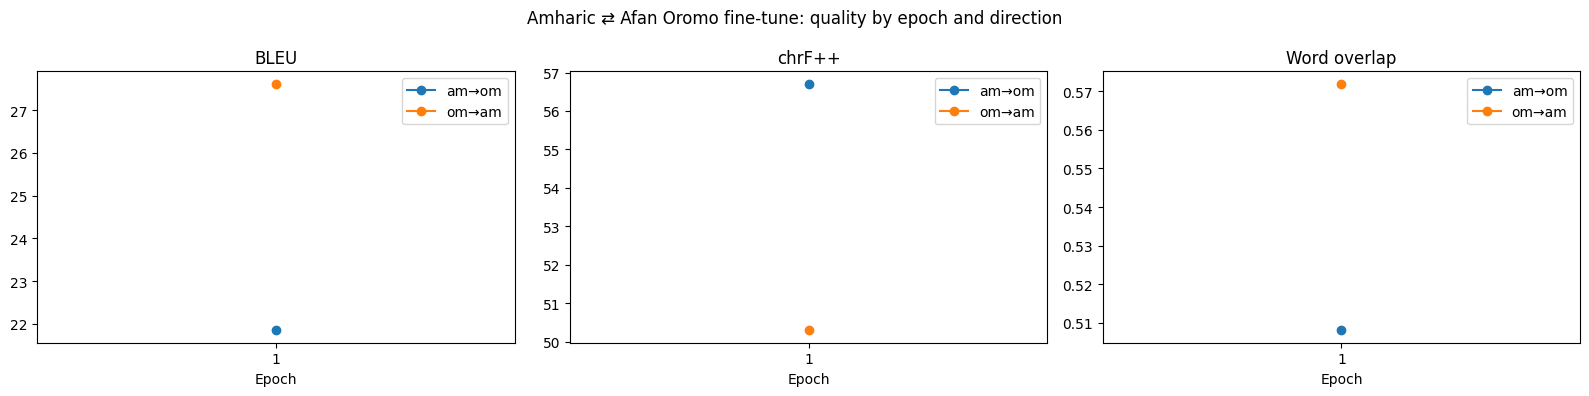

In [13]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
metrics = ["bleu", "chrf++", "word_overlap"]
titles = ["BLEU", "chrF++", "Word overlap"]

for ax, metric, title in zip(axes, metrics, titles):
    for direction in results_df["direction"].unique():
        sub = results_df[results_df["direction"] == direction]
        ax.plot(sub["epoch"], sub[metric], marker="o", label=direction)
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_xticks(sorted(results_df["epoch"].unique()))
    ax.legend()

plt.suptitle("Amharic \u21c4 Afan Oromo fine-tune: quality by epoch and direction")
plt.tight_layout()
plt.savefig("/kaggle/working/eval_curves.png", dpi=150)
plt.show()


## Step 9 — Word/subword alignment heatmap

Generates a translation and, alongside it, plots the decoder's
cross-attention (averaged over heads, last decoder layer) as a heatmap of
*generated token* vs. *source token*. This gives a direct, visual answer to
"is the model actually using word-level context, and which source word is
it attending to for each output word" — useful for explaining/defending the
model in a presentation, and for spotting cases where it's ignoring the
source and hallucinating instead.


/tmp/ipykernel_212/555687443.py:35: UserWarning: Glyph 4768 (\N{ETHIOPIC SYLLABLE GLOTTAL A}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_212/555687443.py:35: UserWarning: Glyph 4811 (\N{ETHIOPIC SYLLABLE WAA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_212/555687443.py:35: UserWarning: Glyph 4674 (\N{ETHIOPIC SYLLABLE QI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_212/555687443.py:35: UserWarning: Glyph 4814 (\N{ETHIOPIC SYLLABLE WO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_212/555687443.py:35: UserWarning: Glyph 4733 (\N{ETHIOPIC SYLLABLE CE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_212/555687443.py:35: UserWarning: Glyph 4723 (\N{ETHIOPIC SYLLABLE TAA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_212/555687443.py:35: UserWarning: Glyph 4619 (\N{ETHIOPIC SYLLABLE LAA}) missing from font(s) DejaVu Sans.
  plt.tight_layou

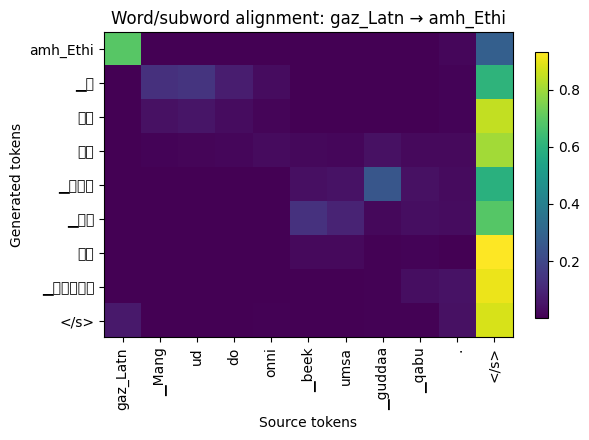

Prediction: አዋቂዎች ታላቅ እውቀት አላቸው።


In [28]:
mdl = AutoModelForSeq2SeqLM.from_pretrained(BEST_DIR, attn_implementation="eager").to(device)
tok = AutoTokenizer.from_pretrained(BEST_DIR)

plot_word_alignment(mdl, tok, "Manguddoonni beekumsa guddaa qabu.", "gaz_Latn", "amh_Ethi")

## Step 10 — Simple bidirectional translate() for demos

A small wrapper so you (or a Flask app, following the same deployment
pattern as the Amharic-English project) can call one function for either
direction.


In [23]:
BEST_DIR = "/kaggle/working/nllb-am-om-epoch2"   # swap to whichever epoch scored best in Step 8

tok = AutoTokenizer.from_pretrained(BEST_DIR)
mdl = AutoModelForSeq2SeqLM.from_pretrained(BEST_DIR).to(device)

LANG = {"am": "amh_Ethi", "om": "gaz_Latn"}

def translate(text, direction="am2om", max_length=96, num_beams=5):
    src, tgt = direction.split("2")
    tok.src_lang = LANG[src]
    inputs = tok(text, return_tensors="pt", truncation=True, max_length=max_length).to(device)
    out = mdl.generate(**inputs, forced_bos_token_id=tok.convert_tokens_to_ids(LANG[tgt]),
                        max_length=max_length, num_beams=num_beams)
    return tok.batch_decode(out, skip_special_tokens=True)[0]

print(translate("\u1201\u1233\u1265 \u12a0\u235e\u12f3\u123d \u12ac\u1275\u120d \u1290\u12cd\u1362", "am2om"))
print(translate("Herrega barumsa.", "om2am"))


Husaas keetii haaraa dha.
የሂሳብ ትምህርት።


## If you hit CUDA OOM with dual-GPU DDP

Same causes/fixes as the Amharic-English project:

1. Lower `per_device_train_batch_size` to `2` (or `1`), raise
   `gradient_accumulation_steps` to compensate.
2. Lower `MAX_LEN` in `train.py` from `96` to `64` — children's sentences
   are short, so this rarely loses real content.
3. Confirm `gradient_checkpointing=True` and `fp16=True` are both still
   set.
4. Restart the session between attempts to clear fragmented CUDA memory.
5. Double check the `transformers==4.57.1` pin actually took effect
   (`import transformers; print(transformers.__version__)`) — if it's
   still v5.x, the kernel needs a restart for the pin to apply.

## A note on "few-parameter" fine-tuning alternatives

If 600M full fine-tuning ever feels like more capacity than an 11.8k-pair
corpus needs (risk of overfitting on such specific children's-topic
sentences), a LoRA/PEFT adapter on top of the same NLLB-200-distilled-600M
backbone is the natural next step — it trains only a few million adapter
parameters instead of all 600M, which further reduces overfitting risk and
produces a much smaller file to distribute (a few MB of adapter weights
instead of a full model copy). Worth trying as a second run to compare
against the full fine-tune above if you have time before the presentation.
